# Лабораторная работа №15: Flow matching и rectified flow

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать 2D rectified flow.
- Визуализировать vector field и trajectories.
- Сравнить Euler steps и diffusion baseline.

## Теоретическая часть

Flow matching обучает vector field $v_\theta(x_t,t)$, переносящий простое распределение в data distribution. Для rectified path $x_t=(1-t)x_0+tx_1$ target velocity равна $x_1-x_0$. Sampling решает ODE.

![Flow matching paths](https://raw.githubusercontent.com/atong01/conditional-flow-matching/main/assets/cfm.png)


Rectified flow строит линейный путь x_t=(1−t)x₀+tx₁ с полем v*=x₁−x₀; интегрирование ODE Euler переносит шум к данным. На двумерном распределении можно оценить покрытие мод и нарисовать траектории; VP diffusion служит отдельно обучаемой контрольной моделью при том же бюджете.

Для VP-пути $x_t=\cos(\pi t/2)x_1+\sin(\pi t/2)\epsilon$. В предельной точке $t=1$ восстановление $x_1$ через деление на $\alpha_t$ не определено: в коде используется явно ограниченное $t\leq0.9$ как приближение шумового старта.

### Экспериментальный протокол

Демонстрационная задача — восьмимодальное 2D распределение, а не MNIST. Полный режим обучает две отдельные модели по 3000 шагов и coupling ablation; smoke — 3 шага, его картинки/метрики не используются в выводах. Все числовые метрики рассчитываются из фактических точек относительно test.

### Материалы

- [Conditional Flow Matching](https://github.com/atong01/conditional-flow-matching)
- [Flow Matching paper](https://arxiv.org/abs/2210.02747)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
SEED = 42
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
# Для 2D-MLP с батчем 512 CPU быстрее, чем MPS (накладные расходы на запуск ядер больше самих вычислений),
# поэтому на Mac работа идёт на CPU; на CUDA-машине код использует GPU.
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', str(Path.cwd().parents[1] / 'data')))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2))
print({'device':DEVICE,'fast_dev_run':FAST_DEV_RUN,'artifacts':str(ARTIFACTS)})

{'device': 'cpu', 'fast_dev_run': False, 'artifacts': 'artifacts'}


### Геометрия восьмимодального распределения

*Вес: 1 балл.*

**Постановка.** На простой двумерной задаче можно непосредственно измерить геометрию распределений и траекторий. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте независимые train/test выборки с фиксированными seed и центрами мод.

**Результат.** Проверяемое состояние «Геометрия восьмимодального распределения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте независимые train/test выборки с фиксированными seed и центрами мод» и его результат доступен следующему этапу.

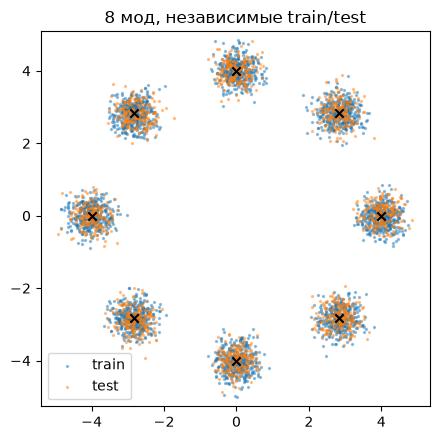

train (20000, 2) test (5000, 2) мод в train: [2524, 2530, 2424, 2502, 2573, 2457, 2499, 2491]


In [2]:
import matplotlib.pyplot as plt

N_MODES, RADIUS, MODE_STD = 8, 4.0, 0.3
CENTERS = torch.tensor([[RADIUS * np.cos(2 * np.pi * k / N_MODES), RADIUS * np.sin(2 * np.pi * k / N_MODES)] for k in range(N_MODES)], dtype=torch.float32)

def sample_modes(n, seed):
    g = torch.Generator().manual_seed(seed)
    k = torch.randint(0, N_MODES, (n,), generator=g)
    return CENTERS[k] + MODE_STD * torch.randn(n, 2, generator=g), k

N_TRAIN, N_TEST = (2000, 1000) if FAST_DEV_RUN else (20000, 5000)
x_train, k_train = sample_modes(N_TRAIN, seed=SEED)          # разные генераторы → независимые выборки
x_test, k_test = sample_modes(N_TEST, seed=SEED + 1000)
assert not torch.isclose(x_train[:100, None], x_test[None, :100]).all(-1).any()
save_json("data_config.json", {"modes": N_MODES, "radius": RADIUS, "std": MODE_STD, "centers": CENTERS.tolist(),
                               "n_train": N_TRAIN, "n_test": N_TEST, "seed_train": SEED, "seed_test": SEED + 1000})
plt.figure(figsize=(4.5, 4.5)); plt.scatter(*x_train[:3000].T, s=2, alpha=0.4, label="train"); plt.scatter(*x_test[:1500].T, s=2, alpha=0.4, label="test")
plt.scatter(*CENTERS.T, c="k", marker="x"); plt.axis("equal"); plt.legend(); plt.title("8 мод, независимые train/test")
plt.tight_layout(); plt.savefig(ARTIFACTS / "data.png", dpi=110); plt.show()
print("train", tuple(x_train.shape), "test", tuple(x_test.shape), "мод в train:", torch.bincount(k_train).tolist())

### Векторное поле и линейный путь

*Вес: 1 балл.*

**Постановка.** На простой двумерной задаче можно непосредственно измерить геометрию распределений и траекторий. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите MLP и визуализируйте линейный путь между шумом и реальными точками.

**Результат.** Проверяемое состояние «Векторное поле и линейный путь» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите MLP и визуализируйте линейный путь между шумом и реальными точками» и его результат доступен следующему этапу.

параметров: 141058


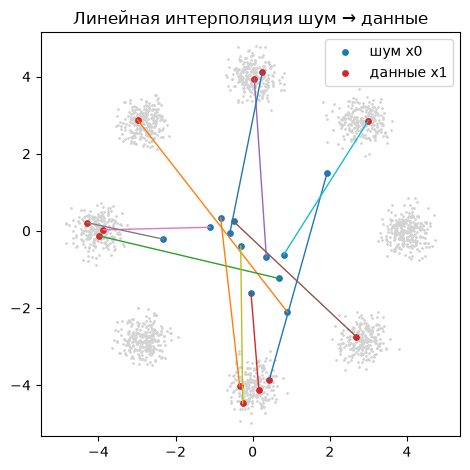

In [3]:
import torch.nn as nn, math

class VelocityMLP(nn.Module):
    """v_θ(x, t): 2D-точка и синусоидальное кодирование времени → 2D-вектор."""
    def __init__(self, hidden=256, t_dim=32):
        super().__init__()
        self.t_dim = t_dim
        self.net = nn.Sequential(nn.Linear(2 + t_dim, hidden), nn.SiLU(), nn.Linear(hidden, hidden), nn.SiLU(),
                                 nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, 2))
    def time_emb(self, t):
        freqs = torch.exp(torch.linspace(0, math.log(1000), self.t_dim // 2, device=t.device))
        ang = t[:, None] * freqs[None]
        return torch.cat([ang.sin(), ang.cos()], 1)
    def forward(self, x, t):
        return self.net(torch.cat([x, self.time_emb(t)], 1))

flow_model = VelocityMLP().to(DEVICE)
print("параметров:", sum(p.numel() for p in flow_model.parameters()))

# линейный путь x_t = (1−t)·x0 + t·x1: x0 — шум, x1 — реальные точки; целевая скорость x1 − x0 постоянна
g = torch.Generator().manual_seed(SEED)
x0_demo = torch.randn(12, 2, generator=g); x1_demo = x_train[:12]
ts = torch.linspace(0, 1, 11)
paths = torch.stack([(1 - t) * x0_demo + t * x1_demo for t in ts])        # [11, 12, 2]
plt.figure(figsize=(4.8, 4.8))
plt.scatter(*x_train[:2000].T, s=1, c="lightgray")
for j in range(12):
    plt.plot(paths[:, j, 0], paths[:, j, 1], "-", lw=1)
plt.scatter(*x0_demo.T, c="tab:blue", s=15, label="шум x0"); plt.scatter(*x1_demo.T, c="tab:red", s=15, label="данные x1")
plt.axis("equal"); plt.legend(); plt.title("Линейная интерполяция шум → данные"); plt.tight_layout()
plt.savefig(ARTIFACTS / "linear_paths.png", dpi=110); plt.show()

### Вторая модель для VP diffusion

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите отдельную модель и два независимых оптимизатора.

**Результат.** Проверяемое состояние «Вторая модель для VP diffusion» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите отдельную модель и два независимых оптимизатора» и его результат доступен следующему этапу.

In [4]:
# та же архитектура, отдельные веса: вторая сеть предсказывает ε для VP-пути
torch.manual_seed(SEED); flow_model = VelocityMLP().to(DEVICE)
torch.manual_seed(SEED + 1); diff_model = VelocityMLP().to(DEVICE)
LR = 1e-3
opt_flow = torch.optim.Adam(flow_model.parameters(), lr=LR)
opt_diff = torch.optim.Adam(diff_model.parameters(), lr=LR)
assert {id(p) for p in flow_model.parameters()}.isdisjoint({id(p) for p in diff_model.parameters()})
print("два независимых оптимизатора Adam, lr =", LR)

def vp_coeffs(t):
    return torch.cos(math.pi * t / 2), torch.sin(math.pi * t / 2)   # α_t, σ_t; t=0 — данные, t=1 — шум

два независимых оптимизатора Adam, lr = 0.001


### Обучение при равном бюджете

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте flow и diffusion на одной train выборке и запишите реальные потери.

**Результат.** Проверяемое состояние «Обучение при равном бюджете» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте flow и diffusion на одной train выборке и запишите реальные потери» и его результат доступен следующему этапу.

In [5]:
STEPS = 3 if FAST_DEV_RUN else 3000
BATCH = 512

def batch_iter(seed):
    g = torch.Generator().manual_seed(seed)
    while True:
        idx = torch.randint(0, N_TRAIN, (BATCH,), generator=g)
        yield x_train[idx], torch.randn(BATCH, 2, generator=g), torch.rand(BATCH, generator=g)

def flow_loss(model, x1, x0, t):
    xt = (1 - t)[:, None] * x0 + t[:, None] * x1
    return ((model(xt, t) - (x1 - x0)) ** 2).sum(1).mean()

def diff_loss(model, x1, eps, t):
    a, s = vp_coeffs(t)
    xt = a[:, None] * x1 + s[:, None] * eps
    return ((model(xt, t) - eps) ** 2).sum(1).mean()

def train(model, opt, loss_fn, name, steps=STEPS, seed=SEED, pairing=None, t_transform=None):
    ckpt = ARTIFACTS / f"{name}.pt"
    hist, start = [], 0
    if ckpt.exists():
        state = torch.load(ckpt, weights_only=False)
        model.load_state_dict(state["model"]); opt.load_state_dict(state["opt"]); hist, start = state["history"], state["step"]
    it = batch_iter(seed)
    for _ in range(start):              # тот же поток батчей после возобновления
        next(it)
    t0 = time.time()
    for step in range(start, steps):
        x1, noise, t = next(it)
        if pairing is not None:
            x1, noise = pairing(x1, noise)
        if t_transform is not None:
            t = t_transform(t)
        loss = loss_fn(model, x1.to(DEVICE), noise.to(DEVICE), t.to(DEVICE))
        opt.zero_grad(); loss.backward(); opt.step()
        hist.append(loss.item())
        if (step + 1) % 500 == 0 or step + 1 == steps:
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "history": hist, "step": step + 1}, ckpt)
    return hist, time.time() - t0

flow_hist, flow_time = train(flow_model, opt_flow, flow_loss, "flow")
diff_hist, diff_time = train(diff_model, opt_diff, diff_loss, "vp_diffusion")
print(f"flow: {len(flow_hist)} шагов за {flow_time:.1f} c, loss {np.mean(flow_hist[:50]):.3f} → {np.mean(flow_hist[-50:]):.3f}")
print(f"VP diffusion: {len(diff_hist)} шагов за {diff_time:.1f} c, loss {np.mean(diff_hist[:50]):.3f} → {np.mean(diff_hist[-50:]):.3f}")

flow: 3000 шагов за 8.1 c, loss 11.383 → 7.407
VP diffusion: 3000 шагов за 8.1 c, loss 1.740 → 0.961


### Фиксация траекторий обучения

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните историю, доступную после возобновления checkpoint.

**Результат.** Проверяемое состояние «Фиксация траекторий обучения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните историю, доступную после возобновления checkpoint» и его результат доступен следующему этапу.

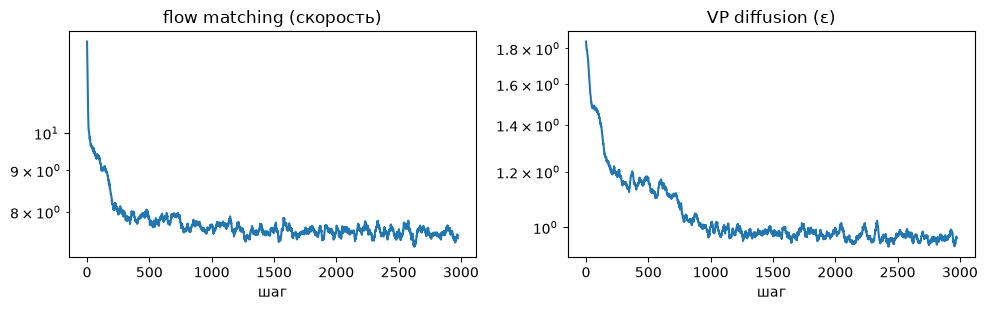

checkpoint flow.pt восстановлен: шаг 3000 история совпадает


In [6]:
save_json("train_history.json", {"flow": {"steps": len(flow_hist), "seconds": flow_time, "loss": flow_hist[::10]},
                                 "vp_diffusion": {"steps": len(diff_hist), "seconds": diff_time, "loss": diff_hist[::10]},
                                 "note": "loss разных параметризаций (скорость и ε) напрямую не сравнимы"})
# проверка, что история и веса восстанавливаются из checkpoint
restored = torch.load(ARTIFACTS / "flow.pt", weights_only=False)
check_model = VelocityMLP(); check_model.load_state_dict(restored["model"])
assert restored["step"] == len(flow_hist) and restored["history"] == flow_hist
assert all(torch.equal(a, b.cpu()) for a, b in zip(check_model.state_dict().values(), flow_model.state_dict().values()))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, h, name in [(axes[0], flow_hist, "flow matching (скорость)"), (axes[1], diff_hist, "VP diffusion (ε)")]:
    ax.plot(np.convolve(h, np.ones(25) / 25, mode="valid")); ax.set_title(name); ax.set_xlabel("шаг"); ax.set_yscale("log")
plt.tight_layout(); plt.savefig(ARTIFACTS / "train_loss.png", dpi=110); plt.show()
print("checkpoint flow.pt восстановлен: шаг", restored["step"], "история совпадает")

### Интеграторы и начальное распределение

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте ODE Euler и обратный шаг VP без сингулярного endpoint; создайте общий шум.

**Результат.** Проверяемое состояние «Интеграторы и начальное распределение» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте ODE Euler и обратный шаг VP без сингулярного endpoint; создайте общий шум» и его результат доступен следующему этапу.

In [7]:
T_MAX_VP = 0.9   # VP-сэмплинг стартует с t=0.9: при t=1 α=0 и восстановление x̂ через деление на α не определено

@torch.no_grad()
def sample_flow(model, z, steps, return_path=False):
    """Явный Эйлер для dx/dt = v_θ(x, t) от t=0 (шум) до t=1 (данные)."""
    x, path = z.clone().to(DEVICE), [z.clone()]
    for i in range(steps):
        t = torch.full((len(x),), i / steps, device=DEVICE)
        x = x + model(x, t) / steps
        path.append(x.cpu())
    return (x.cpu(), torch.stack(path)) if return_path else x.cpu()

@torch.no_grad()
def sample_vp(model, z, steps, return_path=False):
    """Детерминированный обратный шаг VP (DDIM-подобный) по сетке t: T_MAX_VP → 0."""
    grid = torch.linspace(T_MAX_VP, 0.0, steps + 1)
    x, path = z.clone().to(DEVICE), [z.clone()]
    for t_cur, t_next in zip(grid[:-1], grid[1:]):
        t = torch.full((len(x),), float(t_cur), device=DEVICE)
        a, s = vp_coeffs(t)
        eps = model(x, t)
        x_hat = (x - s[:, None] * eps) / a[:, None]       # a ≥ cos(0.45π) ≈ 0.156 > 0
        a2, s2 = vp_coeffs(torch.full((len(x),), float(t_next), device=DEVICE))
        x = a2[:, None] * x_hat + s2[:, None] * eps
        path.append(x.cpu())
    return (x.cpu(), torch.stack(path)) if return_path else x.cpu()

N_GEN = 500 if FAST_DEV_RUN else 5000
z_common = torch.randn(N_GEN, 2, generator=torch.Generator().manual_seed(SEED + 7))   # общий шум для всех сэмплеров
x_check = sample_flow(flow_model, z_common[:4], 1)
assert torch.allclose(x_check, z_common[:4] + flow_model(z_common[:4].to(DEVICE), torch.zeros(4, device=DEVICE)).cpu(), atol=1e-5)
print("общий шум:", tuple(z_common.shape), "| VP стартует с t =", T_MAX_VP)

общий шум: (5000, 2) | VP стартует с t = 0.9


### Оценка покрытия мод на test

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте качество каждого sampler по независимому test и сохраните изображения.

**Результат.** Проверяемое состояние «Оценка покрытия мод на test» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте качество каждого sampler по независимому test и сохраните изображения» и его результат доступен следующему этапу.

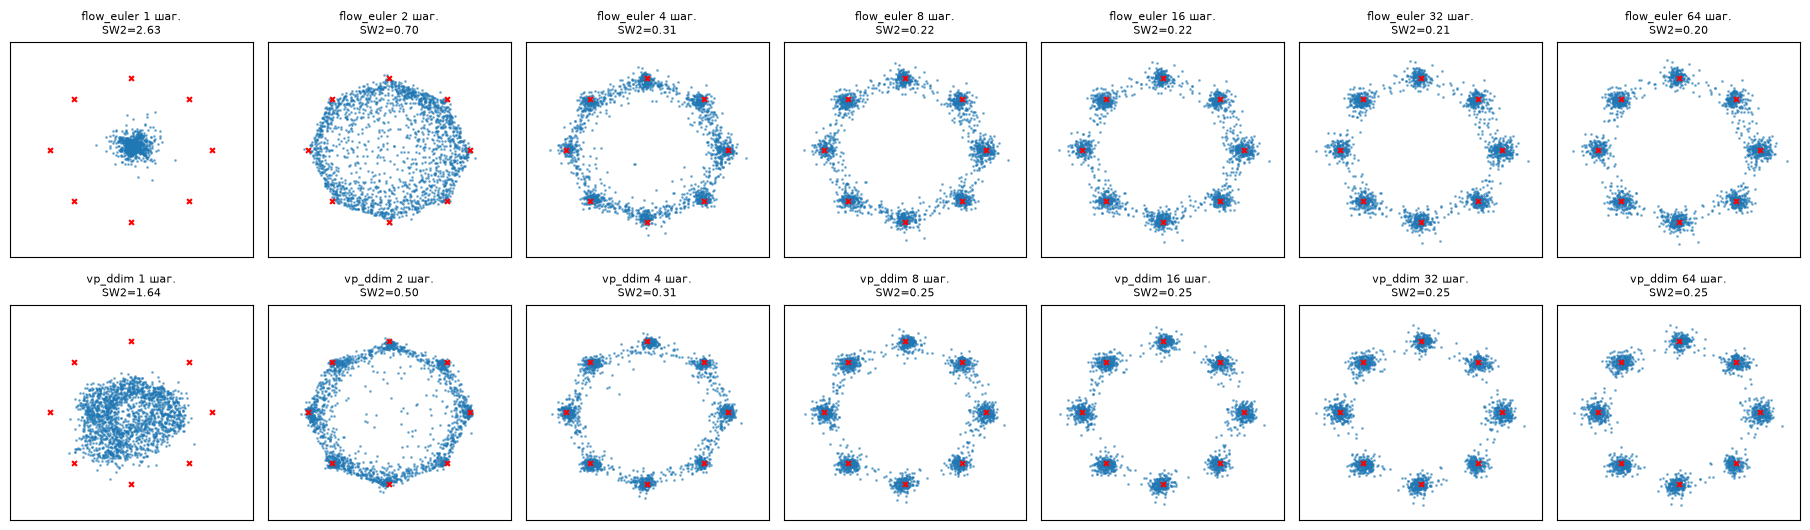

эталон (свежая выборка из истинного распределения): {'sampler': 'test vs fresh sample', 'sliced_w2_to_test': 0.09070798754692078, 'in_mode_rate': 0.9879999756813049, 'modes_covered': 8, 'mode_kl_to_uniform': 0.0004126476123929024}


In [8]:
def assign_modes(x):
    d = torch.cdist(x, CENTERS)
    return d.min(1).values, d.argmin(1)

def sliced_w2(a, b, n_proj=256, seed=0):
    g = torch.Generator().manual_seed(seed)
    dirs = torch.randn(n_proj, 2, generator=g); dirs /= dirs.norm(dim=1, keepdim=True)
    n = min(len(a), len(b))
    pa, pb = torch.sort(a[:n] @ dirs.T, 0).values, torch.sort(b[:n] @ dirs.T, 0).values
    return float(((pa - pb) ** 2).mean().sqrt())

def quality(x):
    dist, mode = assign_modes(x)
    in_mode = dist < 3 * MODE_STD
    counts = torch.bincount(mode[in_mode], minlength=N_MODES).float()
    p = counts / counts.sum().clamp(min=1)
    kl = float((p[p > 0] * (p[p > 0] * N_MODES).log()).sum())
    return {"sliced_w2_to_test": sliced_w2(x, x_test), "in_mode_rate": float(in_mode.float().mean()),
            "modes_covered": int((counts >= 0.02 * len(x)).sum()), "mode_kl_to_uniform": kl}

STEP_GRID = [1, 2, 4, 8, 16, 32, 64]
results, samples = {}, {}
for name, fn, model in [("flow_euler", sample_flow, flow_model), ("vp_ddim", sample_vp, diff_model)]:
    for n in STEP_GRID:
        t0 = time.time(); xs = fn(model, z_common, n); dt = time.time() - t0
        results[f"{name}@{n}"] = {"sampler": name, "steps": n, "nfe": n, "seconds": dt, **quality(xs)}
        samples[(name, n)] = xs
results["test_reference"] = {"sampler": "test vs fresh sample", **quality(sample_modes(N_GEN, seed=SEED + 2000)[0])}
fig, axes = plt.subplots(2, len(STEP_GRID), figsize=(2.6 * len(STEP_GRID), 5.4))
for r, name in enumerate(["flow_euler", "vp_ddim"]):
    for c, n in enumerate(STEP_GRID):
        ax = axes[r, c]; ax.scatter(*samples[(name, n)][:2000].T, s=1, alpha=0.5); ax.scatter(*CENTERS.T, c="r", marker="x", s=12)
        ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{name} {n} шаг.\nSW2={results[f'{name}@{n}']['sliced_w2_to_test']:.2f}", fontsize=8)
plt.tight_layout(); plt.savefig(ARTIFACTS / "samples_by_steps.png", dpi=110); plt.show()
save_json("sampler_quality.json", results)
print("эталон (свежая выборка из истинного распределения):", results["test_reference"])

### Сводная таблица выборок

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните эмпирические метрики выборок и время, не сравнивая напрямую train losses.

**Результат.** Проверяемое состояние «Сводная таблица выборок» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните эмпирические метрики выборок и время, не сравнивая напрямую train losses» и его результат доступен следующему этапу.

In [9]:
import pandas as pd
table = pd.DataFrame({k: v for k, v in results.items() if k != "test_reference"}).T[["sampler", "steps", "nfe", "seconds", "sliced_w2_to_test", "in_mode_rate", "modes_covered", "mode_kl_to_uniform"]]
summary = {"budget": {"train_steps_each": STEPS, "batch": BATCH, "lr": LR, "params_each": sum(p.numel() for p in flow_model.parameters())},
           "train_seconds": {"flow": flow_time, "vp_diffusion": diff_time}, "samplers": results,
           "note": "сравниваются только метрики сэмплов относительно test; train loss двух моделей несопоставимы"}
save_json("summary.json", summary)
print(table.to_string())

                  sampler steps nfe   seconds sliced_w2_to_test in_mode_rate modes_covered mode_kl_to_uniform
flow_euler@1   flow_euler     1   1  0.005092          2.625975          0.0             0                0.0
flow_euler@2   flow_euler     2   2  0.006085           0.70195       0.3342             8            0.00501
flow_euler@4   flow_euler     4   4  0.011594          0.312401       0.7692             8           0.004263
flow_euler@8   flow_euler     8   8  0.024081          0.216953       0.8764             8           0.004125
flow_euler@16  flow_euler    16  16  0.049757          0.218122       0.9086             8           0.003738
flow_euler@32  flow_euler    32  32  0.095743          0.211879       0.9268             8           0.003188
flow_euler@64  flow_euler    64  64  0.194387          0.204555       0.9342             8           0.002758
vp_ddim@1         vp_ddim     1   1  0.003306          1.640435       0.0072             0           1.792606
vp_ddim@2 

### Альтернативное coupling

*Вес: 1 балл.*

**Постановка.** Смена pairing меняет target field при той же конечной выборке; эффект оценивается на распределении сэмплов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите поле с угловым pairing на тех же данных и бюджете.

**Результат.** Проверяемое состояние «Альтернативное coupling» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите поле с угловым pairing на тех же данных и бюджете» и его результат доступен следующему этапу.

In [10]:
def angular_pairing(x1, noise):
    """Сортирую шум и данные батча по полярному углу и сопоставляю по рангу: близкие по углу точки становятся парой."""
    ang_x = torch.atan2(x1[:, 1], x1[:, 0]); ang_n = torch.atan2(noise[:, 1], noise[:, 0])
    return x1[torch.argsort(ang_x)], noise[torch.argsort(ang_n)]

torch.manual_seed(SEED)
flow_ang = VelocityMLP().to(DEVICE)
opt_ang = torch.optim.Adam(flow_ang.parameters(), lr=LR)
ang_hist, ang_time = train(flow_ang, opt_ang, flow_loss, "flow_angular", pairing=angular_pairing)
coupling = {}
for n in STEP_GRID:
    xs = sample_flow(flow_ang, z_common, n)
    coupling[f"angular@{n}"] = {"steps": n, **quality(xs)}
    samples[("flow_angular", n)] = xs
    coupling[f"independent@{n}"] = {k: v for k, v in results[f"flow_euler@{n}"].items() if k != "sampler"}

def straightness(model, z, fine=64):
    """Средний сдвиг одношагового результата от 64-шагового: 0 у идеально прямых траекторий."""
    return float((sample_flow(model, z, 1) - sample_flow(model, z, fine)).norm(dim=1).mean())

coupling["straightness"] = {"independent": straightness(flow_model, z_common), "angular": straightness(flow_ang, z_common)}
coupling["train"] = {"steps": len(ang_hist), "seconds": ang_time}
save_json("coupling_ablation.json", coupling)
print(pd.DataFrame({k: v for k, v in coupling.items() if "@" in k}).T[["steps", "sliced_w2_to_test", "in_mode_rate", "modes_covered"]].to_string())
print("straightness:", coupling["straightness"])

                steps  sliced_w2_to_test  in_mode_rate  modes_covered
angular@1         1.0           0.227153        0.7038            8.0
independent@1     1.0           2.625975        0.0000            0.0
angular@2         2.0           0.178722        0.8106            8.0
independent@2     2.0           0.701950        0.3342            8.0
angular@4         4.0           0.139628        0.8618            8.0
independent@4     4.0           0.312401        0.7692            8.0
angular@8         8.0           0.132298        0.8862            8.0
independent@8     8.0           0.216953        0.8764            8.0
angular@16       16.0           0.126137        0.8988            8.0
independent@16   16.0           0.218122        0.9086            8.0
angular@32       32.0           0.125965        0.9044            8.0
independent@32   32.0           0.211879        0.9268            8.0
angular@64       64.0           0.132339        0.9070            8.0
independent@64   64.

### Поле направлений и траектории

*Вес: 1 балл.*

**Постановка.** Смена pairing меняет target field при той же конечной выборке; эффект оценивается на распределении сэмплов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Изобразите стрелки и траектории; оцените точки из того же исходного шума.

**Результат.** Проверяемое состояние «Поле направлений и траектории» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Изобразите стрелки и траектории; оцените точки из того же исходного шума» и его результат доступен следующему этапу.

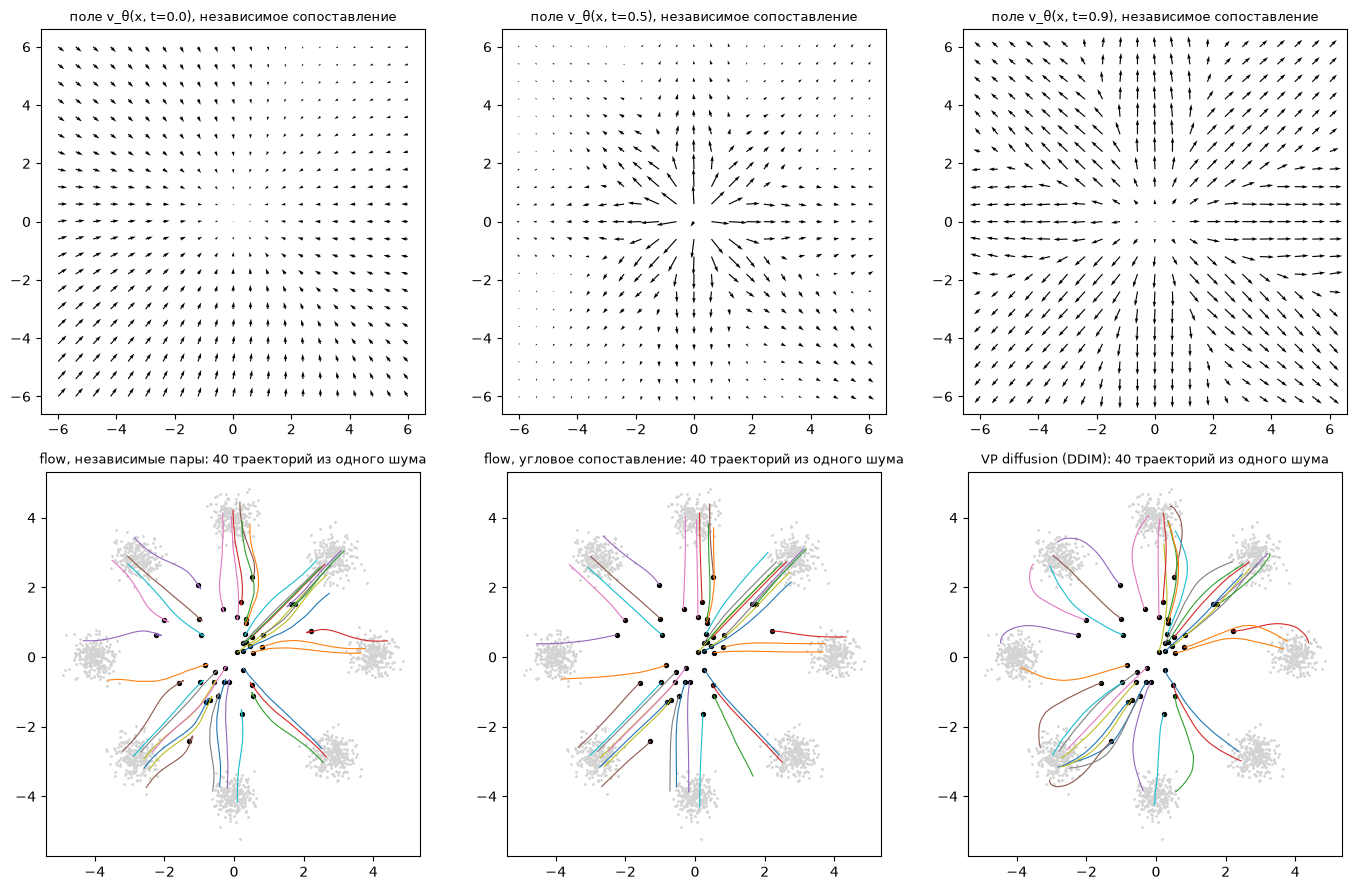

из одного шума: средний сдвиг конечных точек independent vs angular = 0.177


In [11]:
@torch.no_grad()
def field_plot(ax, model, t, title):
    xs, ys = torch.meshgrid(torch.linspace(-6, 6, 21), torch.linspace(-6, 6, 21), indexing="xy")
    grid = torch.stack([xs.flatten(), ys.flatten()], 1)
    v = model(grid.to(DEVICE), torch.full((len(grid),), t, device=DEVICE)).cpu()
    ax.quiver(grid[:, 0], grid[:, 1], v[:, 0], v[:, 1], angles="xy", scale_units="xy", scale=8, width=0.003)
    ax.set_title(title, fontsize=9); ax.set_aspect("equal")

z_traj = z_common[:40]
_, path_ind = sample_flow(flow_model, z_traj, 32, return_path=True)
_, path_ang = sample_flow(flow_ang, z_traj, 32, return_path=True)
_, path_vp = sample_vp(diff_model, z_traj, 32, return_path=True)
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, t in zip(axes[0], (0.0, 0.5, 0.9)):
    field_plot(ax, flow_model, t, f"поле v_θ(x, t={t}), независимое сопоставление")
for ax, path, name in [(axes[1, 0], path_ind, "flow, независимые пары"), (axes[1, 1], path_ang, "flow, угловое сопоставление"), (axes[1, 2], path_vp, "VP diffusion (DDIM)")]:
    ax.scatter(*x_test[:2000].T, s=1, c="lightgray")
    for j in range(len(z_traj)):
        ax.plot(path[:, j, 0], path[:, j, 1], lw=0.8)
    ax.scatter(*path[0].T, s=8, c="k"); ax.set_title(f"{name}: 40 траекторий из одного шума", fontsize=9); ax.set_aspect("equal")
plt.tight_layout(); plt.savefig(ARTIFACTS / "field_and_trajectories.png", dpi=110); plt.show()
end_gap = float((path_ind[-1] - path_ang[-1]).norm(dim=1).mean())
print(f"из одного шума: средний сдвиг конечных точек independent vs angular = {end_gap:.3f}")

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

In [12]:
# Гипотеза (до просмотра результатов): при том же бюджете 3000 шагов выборка t из logit-normal(0, 1), которая
# чаще обучает середину пути, улучшит качество Эйлера при малом числе шагов по сравнению с равномерным t.
# Меняется один фактор — распределение t; данные, seed, поток батчей, архитектура и число шагов те же.
def logit_normal(u):
    return torch.sigmoid(math.sqrt(2) * torch.erfinv((2 * u - 1).clamp(-0.999999, 0.999999)))

torch.manual_seed(SEED)
flow_ln = VelocityMLP().to(DEVICE)
opt_ln = torch.optim.Adam(flow_ln.parameters(), lr=LR)
ln_hist, ln_time = train(flow_ln, opt_ln, flow_loss, "flow_logitnormal", t_transform=logit_normal)
bonus = {"hypothesis": "logit-normal t улучшает качество при 1–8 шагах Эйлера", "steps_budget": len(ln_hist), "rows": {}}
for n in STEP_GRID:
    bonus["rows"][n] = {"uniform_sw2": results[f"flow_euler@{n}"]["sliced_w2_to_test"],
                        "logitnormal_sw2": quality(sample_flow(flow_ln, z_common, n))["sliced_w2_to_test"],
                        "uniform_in_mode": results[f"flow_euler@{n}"]["in_mode_rate"],
                        "logitnormal_in_mode": quality(sample_flow(flow_ln, z_common, n))["in_mode_rate"]}
save_json("bonus_timesampling.json", bonus)
print(pd.DataFrame(bonus["rows"]).T.round(4).to_string())

    uniform_sw2  logitnormal_sw2  uniform_in_mode  logitnormal_in_mode
1        2.6260           2.0665           0.0000               0.0010
2        0.7019           0.4135           0.3342               0.5876
4        0.3124           0.2817           0.7692               0.8328
8        0.2170           0.2496           0.8764               0.8960
16       0.2181           0.2591           0.9086               0.9280
32       0.2119           0.2668           0.9268               0.9442
64       0.2046           0.2587           0.9342               0.9512


## Анализ результатов

**Постановка и бюджет.** 8 гауссовских мод на окружности радиуса 4 (σ=0,3), независимые train (20 000, seed 42) и test (5 000, seed 1042). Обе модели — одинаковые MLP (141 тыс. параметров, синусоидальное кодирование t), 3 000 шагов Adam, batch 512, lr 1e-3, одинаковый поток батчей. Flow matching учит скорость на прямом пути шум→данные, VP-диффузия учит ε на пути x_t = cos(πt/2)·x₁ + sin(πt/2)·ε. Обучение каждой модели на CPU M3 Max занимает около 8 с. Значения loss у двух параметризаций разные по смыслу и не сравниваются.

**Качество сэмплов относительно test** (общий шум, 5 000 точек; SW2 — sliced Wasserstein-2, in-mode — доля точек ближе 3σ к центру моды; у свежей выборки из истинного распределения SW2 = 0,091, in-mode = 0,988):

| шаги (NFE) | flow: SW2 | flow: in-mode | VP: SW2 | VP: in-mode |
|---:|---:|---:|---:|---:|
| 1 | 2,63 | 0,00 | 1,64 | 0,01 |
| 2 | 0,70 | 0,33 | 0,50 | 0,67 |
| 4 | 0,31 | 0,77 | 0,31 | 0,88 |
| 8 | 0,22 | 0,88 | 0,25 | 0,94 |
| 16 | 0,22 | 0,91 | 0,25 | 0,95 |
| 64 | 0,20 | 0,93 | 0,25 | 0,96 |

- Обе модели покрывают все 8 мод начиная с 2 шагов, KL распределения по модам к равномерному ≤ 0,02.
- При 1 шаге обе схлопываются: Эйлер для flow с независимыми парами переносит шум в условное среднее E[x₁ − x₀ | x₀], то есть к центру окружности.
- VP-сэмплер даёт более «плотные» моды (in-mode выше), а flow — чуть лучший SW2 при большом числе шагов. Причина в разном старте: VP начинает с t = 0,9, где α ≈ 0,16, и остаточный сигнал данных игнорируется. Стоимость шага одинакова: время линейно по NFE, около 3 мс на шаг для 5 000 точек.

**Coupling-абляция (угловое сопоставление в батче, тот же бюджет).** Траектории становятся почти прямыми: средний сдвиг одношагового результата от 64-шагового — 0,44 против 3,74 у независимых пар. Уже за 1 шаг: SW2 0,23, in-mode 0,70 (у независимых пар 2,63 и 0,00), за 4 шага — 0,14 против 0,31. При большом числе шагов SW2 лучше (0,13 против 0,20), а in-mode чуть ниже (0,91 против 0,93): соседние по углу пары тянут точки к краям мод. На рисунке `field_and_trajectories.png` видно, что у независимых пар траектории сначала идут к центру и потом расходятся, а у углового сопоставления идут сразу к своей моде.

**Бонус — logit-normal t** (меняется только распределение времени при обучении). При 2–4 шагах качество лучше (SW2 0,41 против 0,70 при 2 шагах, 0,28 против 0,31 при 4), in-mode выше на всех бюджетах. Но при ≥8 шагах SW2 хуже (0,25–0,27 против 0,20–0,22): края интервала t обучаются реже, и мелкая структура мод восстанавливается хуже. Гипотеза подтвердилась только для малого числа шагов.

**Неудачные случаи:** (1) 1 шаг, независимые пары — все точки в центре; (2) VP при 1 шаге — размытое облако радиуса ≈2 вокруг центра, ни одной точки в модах; (3) 2 шага flow — «заполненный восьмиугольник»: две трети точек лежат между центром и модами; (4) угловое сопоставление — точки «размазываются» вдоль окружности к соседним модам; (5) logit-normal при 64 шагах — сдвиг масштаба мод, отсюда рост SW2.

**Ограничения:** двумерная игрушечная задача, одна архитектура и один seed; SW2 по 5 000 точкам имеет «пол» около 0,09.

### Выводы

1. Rectified flow и VP-диффузия при равном бюджете обучения дают сопоставимое качество при ≥8 шагах; flow лучше по SW2, VP плотнее держит моды.
2. Число шагов критично для обоих: 1–2 шага Эйлера с независимым сопоставлением не работают из-за кривизны траекторий.
3. Выбор coupling — главный рычаг для малого числа шагов: угловое сопоставление выпрямляет траектории в 8,5 раз и даёт приличный результат за 1 шаг.
4. Распределение t при обучении смещает компромисс: logit-normal улучшает 2–4 шага ценой точности при длинном интегрировании.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.